### Lab 9 Meeting 2 ###

In [4]:
import matplotlib.pyplot as plt
import numpy as np

from qiskit_nature.second_q.drivers import PySCFDriver
from qiskit_nature.units import DistanceUnit
from qiskit_nature.second_q.mappers import JordanWignerMapper
from qiskit_algorithms import VQE
from qiskit_algorithms.optimizers import SLSQP
from qiskit.circuit.library import n_local
from qiskit.primitives import StatevectorEstimator

In [ ]:
bond_lengths = np.linspace(0.4, 2.2, 8)
energies = []

for R in bond_lengths:
    driver = PySCFDriver(
        atom=f"H 0 0 0; H 0 0 {R}",
        basis = "sto3g",
        unit = DistanceUnit.ANGSTROM
    )

    mapper = JordanWignerMapper()

    ansatz = n_local(
        num_qubits = 4,
        rotation_blocks=["ry", "rz"],
        entanglement_blocks='cz',
        entanglement='linear',
        reps=3,
        insert_barriers=True
    )

    optimizer = SLSQP(maxiter=100)
    estimator = StatevectorEstimator()
    vqe = VQE(
        estimator=estimator,
        ansatz=ansatz,
        optimizer=optimizer
    )

    problem = driver.run()
    qubit_op = mapper.map(problem.hamiltonian.second_q_op())

    result = vqe.compute_minimum_eigenvalue(qubit_op)
    energy = result.eigenvalue.real + problem.nuclear_repulsion_energy
    energies.append(energy)


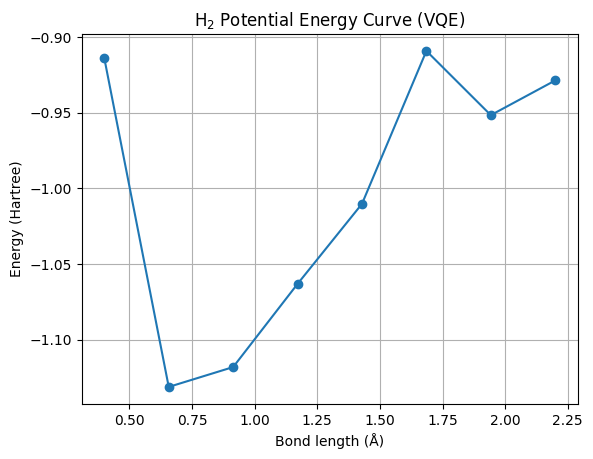

In [29]:
plt.plot(bond_lengths, energies, 'o-')
plt.xlabel("Bond length (\u212B)")
plt.ylabel("Energy (Hartree)")
plt.title("H$_2$ Potential Energy Curve (VQE)")
plt.grid()
plt.show()

### Task B

In [31]:
## Changing the Ansatz

from qiskit.circuit.library import EfficientSU2
ansatz = EfficientSU2(num_qubits=4, reps = 2)
ansatz.draw("mpl")
bond_lengths_new_ansatz = np.linspace(0.4, 2.2, 8)
energies_new_ansatz = []

for R in bond_lengths_new_ansatz:
    driver = PySCFDriver(
        atom=f"H 0 0 0; H 0 0 {R}",
        basis = "sto3g",
        unit = DistanceUnit.ANGSTROM
    )

    mapper = JordanWignerMapper()

    optimizer = SLSQP(maxiter=100)
    estimator = StatevectorEstimator()
    vqe = VQE(
        estimator=estimator,
        ansatz=ansatz,
        optimizer=optimizer
    )

    problem = driver.run()
    qubit_op = mapper.map(problem.hamiltonian.second_q_op())

    result_new_ansatz = vqe.compute_minimum_eigenvalue(qubit_op)
    energy_new_ansatz = result_new_ansatz.eigenvalue.real + problem.nuclear_repulsion_energy
    energies_new_ansatz.append(energy_new_ansatz)


/tmp/ipykernel_177284/932177276.py:4: DeprecationWarning: The class ``qiskit.circuit.library.n_local.efficient_su2.EfficientSU2`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. Use the function qiskit.circuit.library.efficient_su2 instead.
  ansatz = EfficientSU2(num_qubits=4, reps = 2)


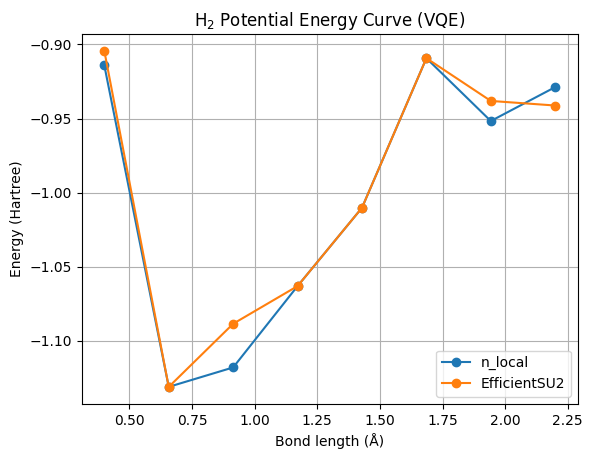

In [32]:
plt.plot(bond_lengths, energies, 'o-', label="n_local")
plt.plot(bond_lengths_new_ansatz, energies_new_ansatz, 'o-', label="EfficientSU2")
plt.xlabel("Bond length (\u212B)")
plt.ylabel("Energy (Hartree)")
plt.title("H$_2$ Potential Energy Curve (VQE)")
plt.legend()
plt.grid()
plt.show()

In [ ]:
## Changing the optimizer
from qiskit_algorithms.optimizers import COBYLA

ansatz = EfficientSU2(num_qubits=4, reps = 2)
optimizer = COBYLA(maxiter = 200)

bond_lengths_new_optimizer = np.linspace(0.4, 2.2, 8)
energies_new_optimizer = []

for R in bond_lengths_new_optimizer:
    driver = PySCFDriver(
        atom=f"H 0 0 0; H 0 0 {R}",
        basis = "sto3g",
        unit = DistanceUnit.ANGSTROM
    )

    mapper = JordanWignerMapper()

    estimator = StatevectorEstimator()
    vqe = VQE(
        estimator=estimator,
        ansatz=ansatz,
        optimizer=optimizer
    )

    problem = driver.run()
    qubit_op = mapper.map(problem.hamiltonian.second_q_op())

    result_new_optimizer = vqe.compute_minimum_eigenvalue(qubit_op)
    energy_new_optimizer = result_new_optimizer.eigenvalue.real + problem.nuclear_repulsion_energy
    energies_new_optimizer.append(energy_new_optimizer)


/tmp/ipykernel_177284/3197943230.py:4: DeprecationWarning: The class ``qiskit.circuit.library.n_local.efficient_su2.EfficientSU2`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. Use the function qiskit.circuit.library.efficient_su2 instead.
  ansatz = EfficientSU2(num_qubits=4, reps = 2)


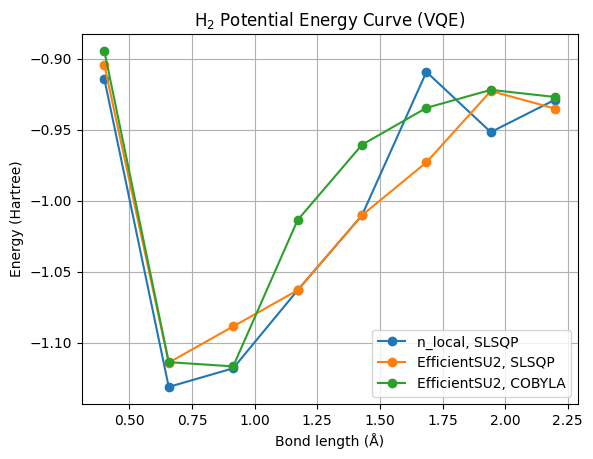

In [19]:
plt.plot(bond_lengths, energies, 'o-', label="n_local, SLSQP")
plt.plot(bond_lengths_new_ansatz, energies_new_ansatz, 'o-', label="EfficientSU2, SLSQP")
plt.plot(bond_lengths_new_optimizer, energies_new_optimizer, 'o-', label="EfficientSU2, COBYLA")
plt.xlabel("Bond length (\u212B)")
plt.ylabel("Energy (Hartree)")
plt.title("H$_2$ Potential Energy Curve (VQE)")
plt.legend()
plt.grid()
plt.show()

#### Task C Benchmarking and Interprtation

In [35]:
from qiskit_algorithms import NumPyMinimumEigensolver
exact = NumPyMinimumEigensolver()

ansatz = EfficientSU2(num_qubits=4, reps = 2)
optimizer = COBYLA(maxiter = 200)

bond_lengths = np.linspace(0.4, 2.2, 8)
exact_energies = []

for R in bond_lengths:
    driver = PySCFDriver(
        atom=f"H 0 0 0; H 0 0 {R}",
        basis = "sto3g",
        unit = DistanceUnit.ANGSTROM
    )

    problem = driver.run()
    qubit_op = mapper.map(problem.hamiltonian.second_q_op())
    exact_result = exact.compute_minimum_eigenvalue(qubit_op)
    exact_energy = exact_result.eigenvalue.real + problem.nuclear_repulsion_energy
    exact_energies.append(exact_energy)

/tmp/ipykernel_177284/2756386934.py:4: DeprecationWarning: The class ``qiskit.circuit.library.n_local.efficient_su2.EfficientSU2`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. Use the function qiskit.circuit.library.efficient_su2 instead.
  ansatz = EfficientSU2(num_qubits=4, reps = 2)


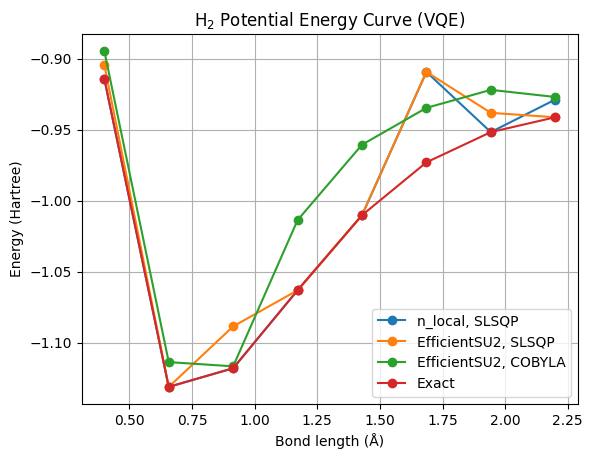

In [36]:
plt.plot(bond_lengths, energies, 'o-', label="n_local, SLSQP")
plt.plot(bond_lengths_new_ansatz, energies_new_ansatz, 'o-', label="EfficientSU2, SLSQP")
plt.plot(bond_lengths_new_optimizer, energies_new_optimizer, 'o-', label="EfficientSU2, COBYLA")
plt.plot(bond_lengths, exact_energies, 'o-', label="Exact")
plt.xlabel("Bond length (\u212B)")
plt.ylabel("Energy (Hartree)")
plt.title("H$_2$ Potential Energy Curve (VQE)")
plt.legend()
plt.grid()
plt.show()